# Range-dependence of pile driving pulse receptions

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [3]:
fname = Path("results/events/metrics.csv")
df = pd.read_csv(fname)

print(df.columns)
print(f"{len(df):,} rows in dataframe.")

Index(['index', 'uid', 'station', 'channel', 'time_init', 'time_end', 'unit',
       'RL_rms', 'RL_pk', 'RL_pkpk', 'SEL', 't_rise', 't_decay', 'kurtosis',
       'SEL_cum', 'event_name', 'event_site', 'filter', 'filter_freq',
       'range'],
      dtype='object')
342,271 rows in dataframe.


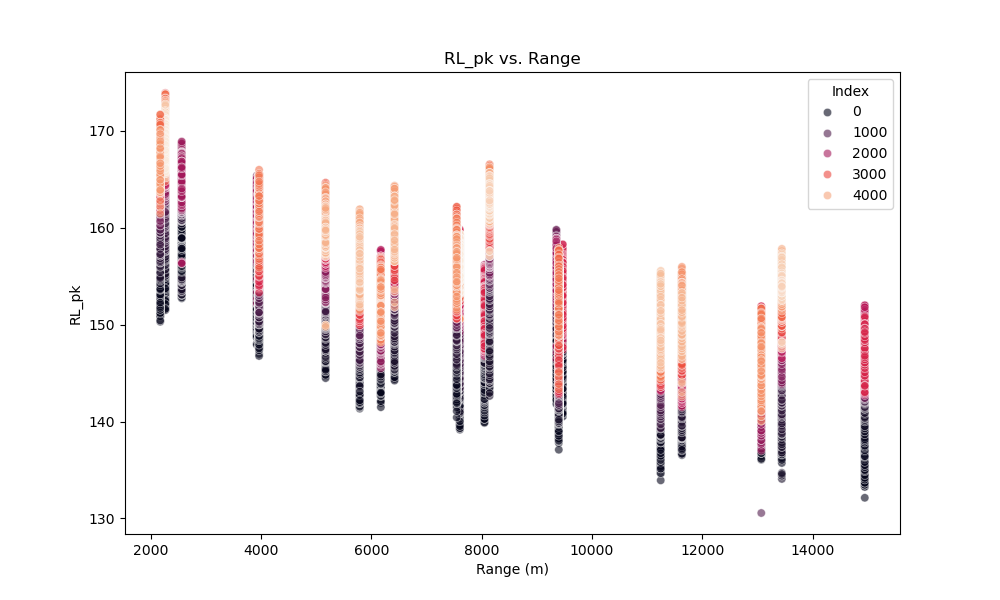

In [4]:
def plot_rl_pkpk_vs_range(df):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=df, x="range", y="RL_pk", hue="index", palette="rocket", alpha=0.6)
    plt.title("RL_pk vs. Range")
    plt.xlabel("Range (m)")
    plt.ylabel("RL_pk")
    plt.legend(title="Index")
    plt.show()

# Call the function to plot
plot_rl_pkpk_vs_range(df)

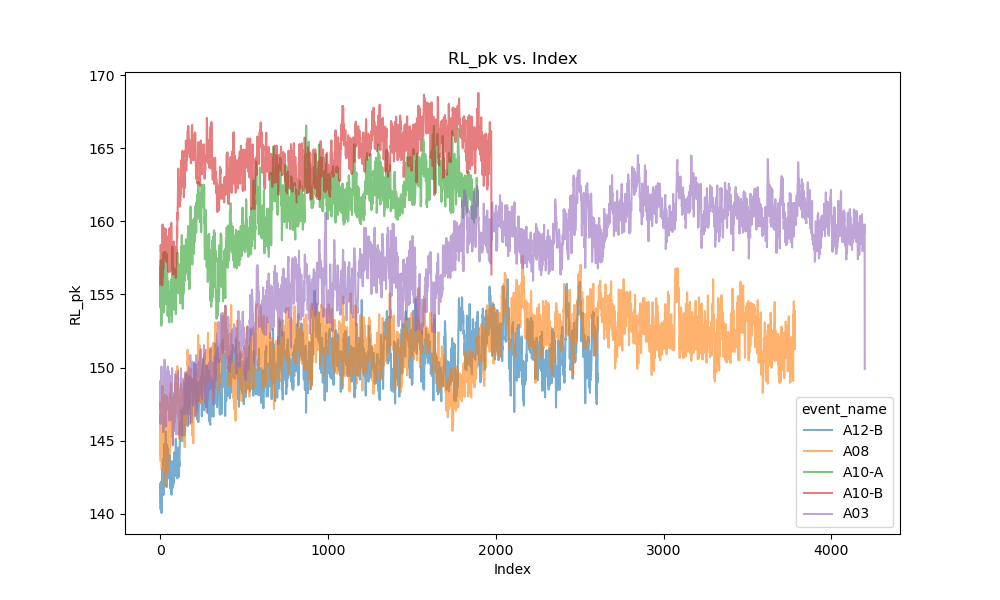

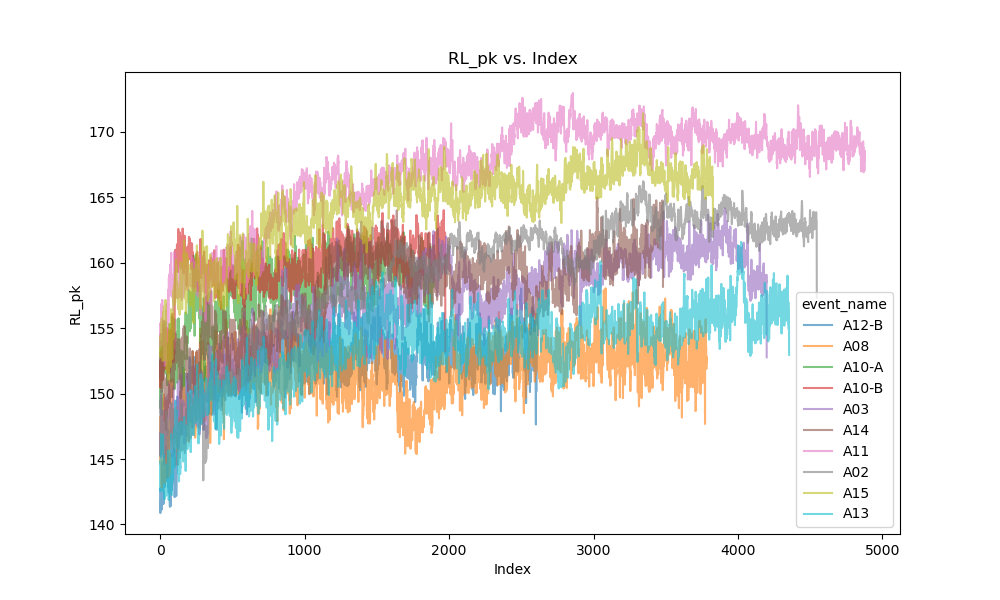

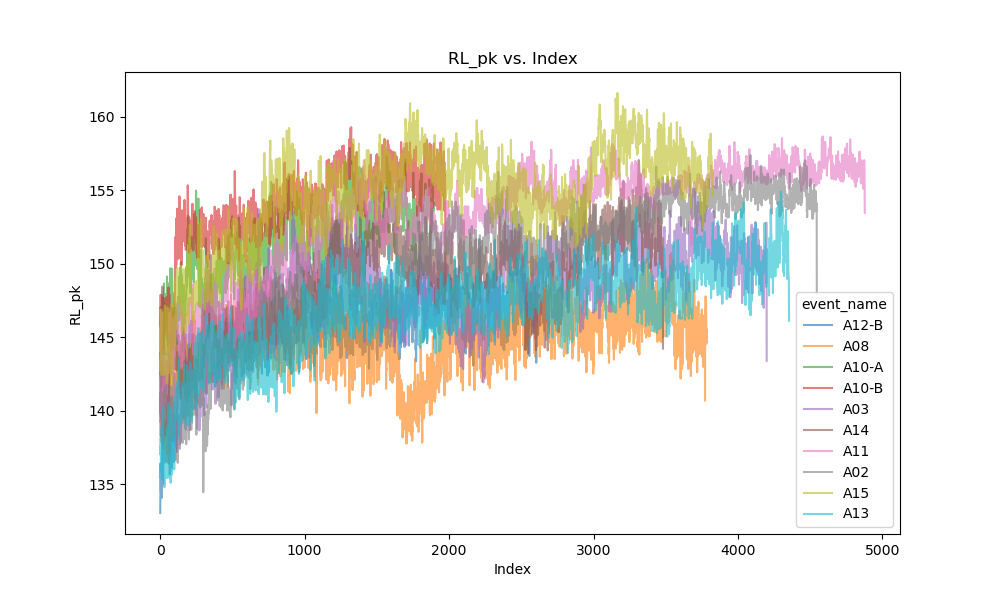

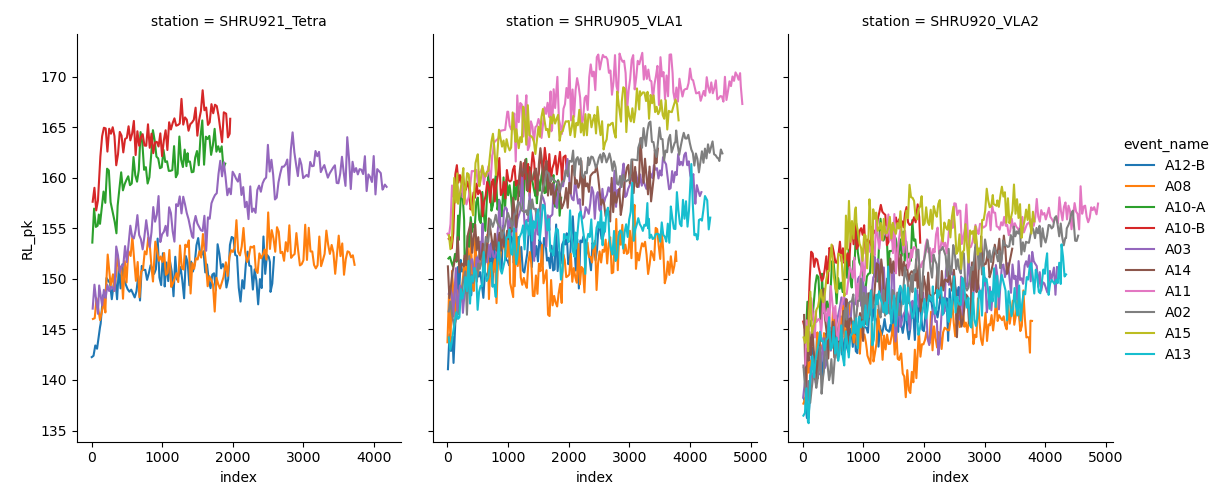

In [5]:
def rel_lineplot(df):
    # palette = sns.color_palette("rocket", n_colors=df["event_name"].nunique())
    
    sns.relplot(
        data=df,
        x="index",
        y="RL_pk",
        hue="event_name",
        col="station",
        kind="line",
        # palette=palette,
        height=5,
        aspect=0.75,
        errorbar=None,
        facet_kws=dict(sharex=False),
    )
    plt.show()



def plot_rl_pkpk_vs_index(df):
    plt.figure(figsize=(10, 6))
    sns.lineplot(data=df, x="index", y="RL_pk", hue="event_name", alpha=0.6, errorbar=None)
    plt.title("RL_pk vs. Index")
    plt.xlabel("Index")
    plt.ylabel("RL_pk")
    plt.show()

# Call the function to plot
plot_rl_pkpk_vs_index(df[df["station"] == "SHRU921_Tetra"])
plot_rl_pkpk_vs_index(df[df["station"] == "SHRU905_VLA1"])
plot_rl_pkpk_vs_index(df[df["station"] == "SHRU920_VLA2"])
rel_lineplot(df.iloc[::100, :])

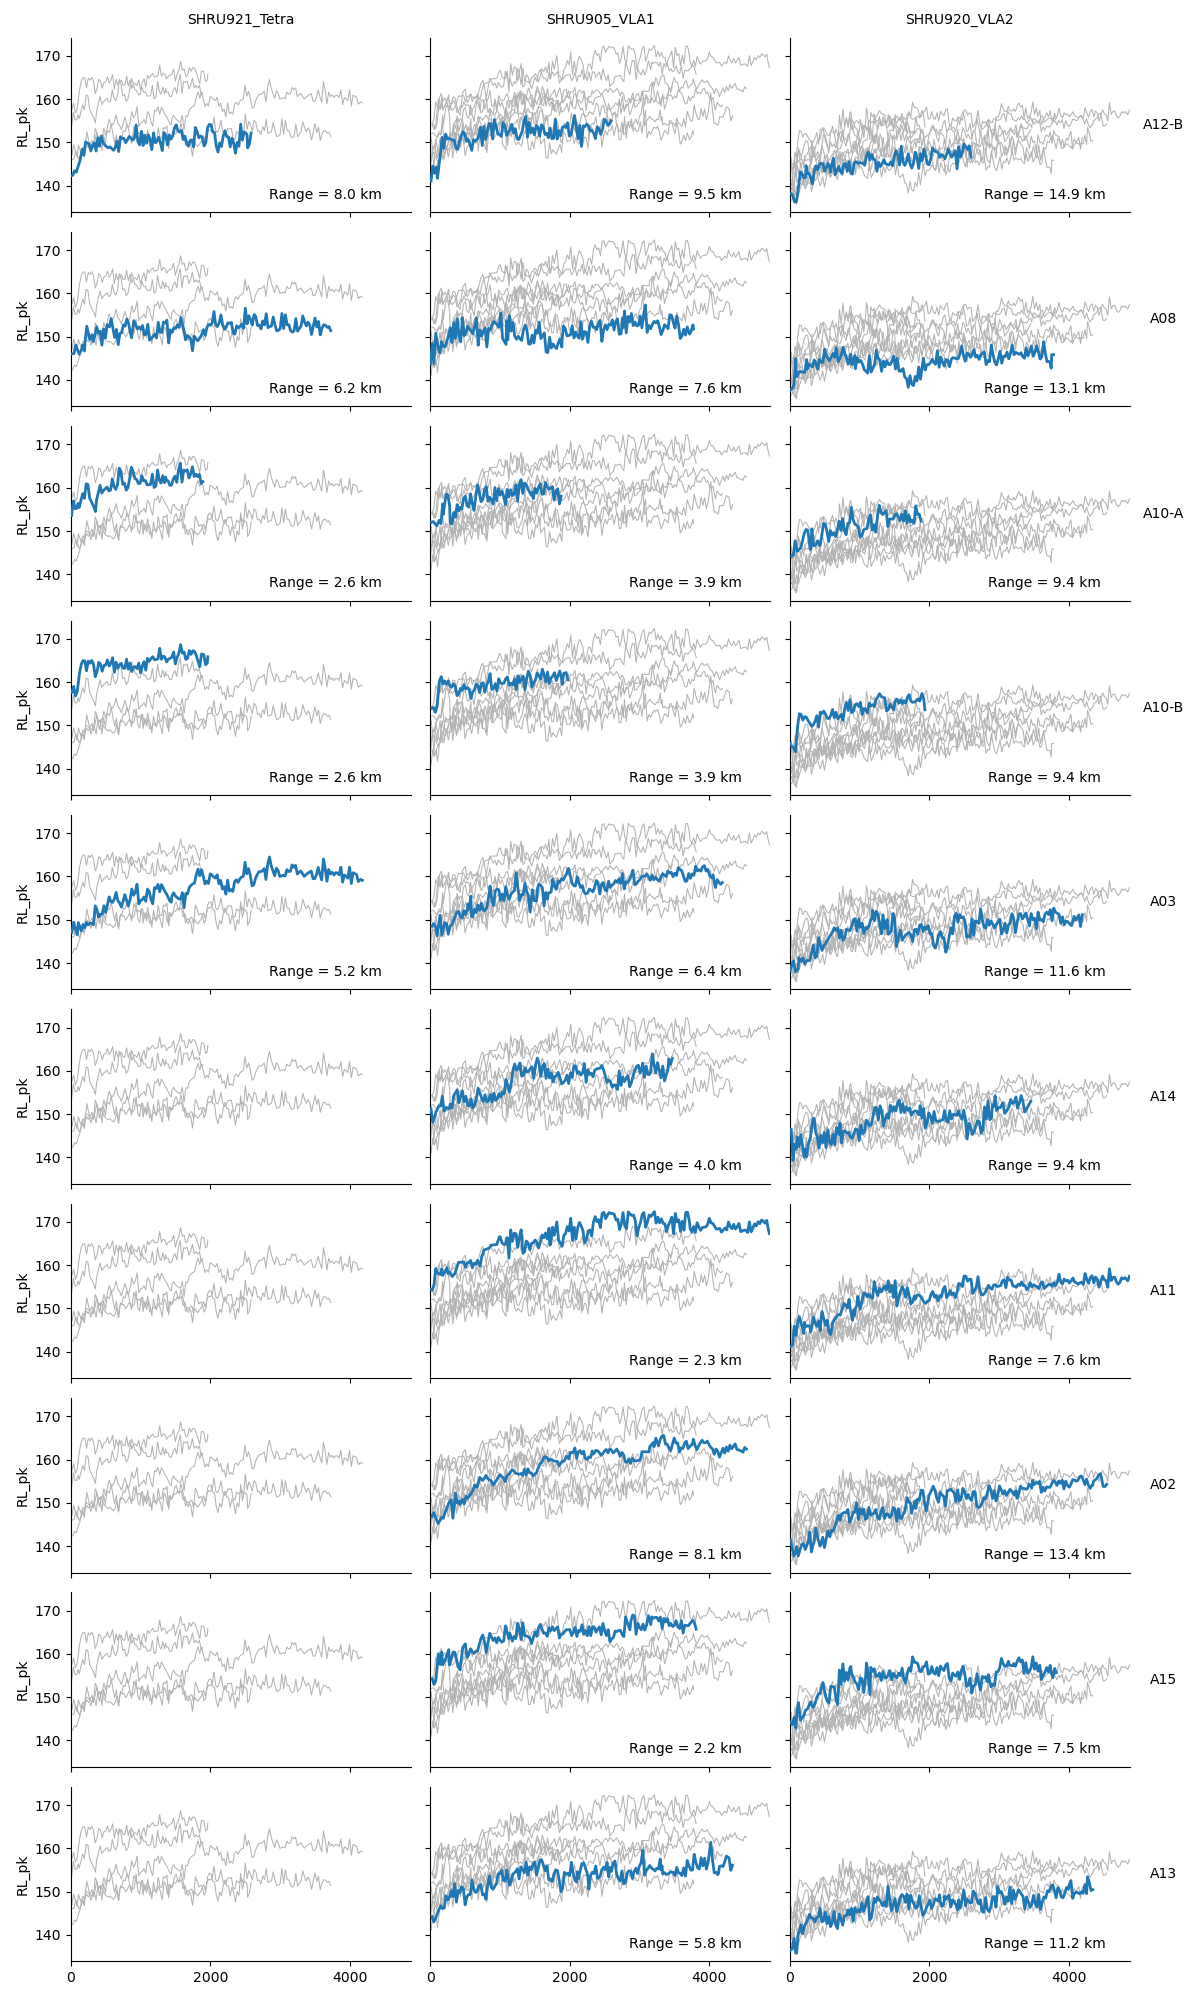

In [6]:
def plot_rel_lineplot(df):
    g = sns.relplot(
        data=df,
        x="index",
        y="RL_pk",
        col="station",
        row="event_name",
        kind="line",
        # hue="event_name",
        # palette="rocket",
        linewidth=2.0,
        zorder=5,
        height=2,
        aspect=2,
        legend=False,
        errorbar=None,
    )

    for i, ((event, station), ax) in enumerate(g.axes_dict.items()):
        sns.lineplot(
            data=df[df["station"] == station],
            x="index",
            y="RL_pk",
            units="event_name",
            estimator=None,
            color=".7",
            linewidth=0.75,
            ax=ax,
        )
        ax.set_xlim(0, df["index"].max())
        
        try:
            r_sta = df_plot[(df_plot["station"] == station) & (df_plot["event_name"] == event)]["range"].values[0]
            ax.text(0.75, 0.1, f"Range = {r_sta / 1000:.1f} km", ha="center", va="center", transform=ax.transAxes)
        except IndexError:
            pass

        if i < 3:
            ax.text(0.5, 1.1, station, ha="center", va="center", transform=ax.transAxes)
        if (i + 1) % 3 == 0:
            ax.text(1.1, 0.5, event, ha="center", va="center", transform=ax.transAxes)

    ax.set_xticks(ax.get_xticks()[::2])

    g.set_titles("")
    g.set_axis_labels("", "RL_pk")
    g.tight_layout()

    plt.show()


# Call the function to plot
df_plot = df.iloc[::100, :]
plot_rel_lineplot(df_plot)